# Meta-model: ordonare, sizing și comparația cu prior-ul

**De ce acest notebook.** În `solid/cross_asset_transfer_meta_labeling.ipynb` am concluzis că meta-labeling-ul „nu aduce nimic față de
prior”. Concluzia se baza pe log loss, pe AUC calculat pe celule mici și pe filtre binare. Nu măsurase nici ordonarea
tranzacțiilor, nici valoarea economică a unui sizing. O reluare a analizei a arătat un semnal slab de ordonare, cu valoare
economică mică. Aici îl testăm cum trebuie:

1. **Ordonarea**: coeficientul de informație (IC) dintre probabilitatea prezisă și randament, în interiorul aceleiași strategii și
   ferestre de timp.
2. **Valoarea economică**: sizing proporțional cu rangul probabilității, față de (a) aceeași mărime pentru toate tranzacțiile,
   (b) un sizing făcut doar cu rata de câștig istorică a activului („prior pe activ”), (c) dimensionarea invers proporțională cu
   volatilitatea, singura componentă confirmată în notebook-ul anterior.
3. **Legătura dintre log loss și economie**: în ce măsură log loss-ul prezice câștigul economic.

**Cum evităm greșeala de supra-selecție.** Perioada 2017–2026 și cele 20 de active au fost folosite de multe ori, deci rezultatele
pe ele sunt „văzute”. Dovezile **curate** vin din două surse:

* **20 de active noi**, pe care nu le-am folosit în nicio analiză (ALGO, VET, THETA, SAND, MANA, AXS, ICP, HBAR, CRV, GRT, ENJ,
  CHZ, ZEC, DASH, XTZ, COMP, SNX, IOTA, ZIL, QTUM). Modelul se antrenează **doar pe cele 20 vechi** și prezice pe cele noi
  (transfer pur, ca regimul `OTHERS` din notebook-ul inițial). Aceasta este și întrebarea inițială: se transmite informația
  între active?
* **Perioada C** (după 2026-09-01), dar are doar ~3 luni, deci nu poate decide.

Specificația (model, reguli de sizing, ipoteze, criterii de decizie) a fost **scrisă și înghețată înainte de prima rulare** în
`meta_labeling_sizing_vs_prior_FROZEN_SPEC.md`. Notebook-ul verifică amprenta ei.

**Rezultatul pe scurt** (cifre și discuție în concluziile de la final):

* Modelul antrenat pe 20 de active, aplicat pe **20 de active noi**, separă tranzacțiile mai bune de cele mai slabe (rata de
  câștig 0.309 → 0.374 de la prima la ultima cvintilă a lui `p`; randament +296 bps [+111, +477]) și, folosit pentru **sizing**,
  bate mărimea uniformă (**+0.116 Sharpe**, permutare p < 0.001), **dar probabilitatea lui nu e mai bună decât prior-ul în
  log loss** (+0.0006).
* Din cele 4 ipoteze înghețate se confirmă **H2** (sizing pe rang bate sizing uniform) și **H4** (adaugă peste dimensionarea
  invers-vol), nu se confirmă **H1** (IC față de randament) și **H3** (față de prior-ul pe activ, la limită).
* **Dar o explorare post-hoc arată că valoarea este în mare parte volatilitate**: un model cu o singură variabilă (volatilitatea)
  face la fel de bine sau mai bine decât M1, iar M1 nu adaugă nimic peste el (pe B chiar pierde, −0.105 Sharpe).
* Efectul este de regim: puternic în 2019–2021, slab după. **Log loss-ul nu prezice câștigul economic** (Spearman +0.11 pe
  30 de modele; IC față de randament: +0.64).

## Configurare

In [1]:
import hashlib, json, sys, time, urllib.request, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import spearmanr
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import QuantileTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import HistGradientBoostingClassifier


def find_project_root():
    for path in [Path.cwd(), *Path.cwd().parents]:
        if (path / "quant_forge/strategies").exists():
            return path
    raise FileNotFoundError("QuantForge project root not found")


ROOT = find_project_root()
try:
    import quant_forge.strategies as qs
except ImportError:
    sys.path.insert(0, str(ROOT))
    import quant_forge.strategies as qs

SPEC = ROOT / "research/meta-labeling/meta_labeling_sizing_vs_prior_FROZEN_SPEC.md"
SPEC_SHA256 = "fe14d53ac9ea39cab3574c5faf9ee18877d905312a28d9c0131558ae60b609a2"
KLINES_DIR = Path.home() / ".cache/quantforge/binance_klines_4h"
SEEN = ["BTC", "ETH", "BNB", "SOL", "XRP", "ADA", "AVAX", "BCH", "DOGE", "DOT", "LINK", "LTC", "UNI",
        "AAVE", "ATOM", "ETC", "FIL", "NEAR", "TRX", "XLM"]
NEW = ["ALGO", "VET", "THETA", "SAND", "MANA", "AXS", "ICP", "HBAR", "CRV", "GRT", "ENJ", "CHZ", "ZEC", "DASH", "XTZ",
       "COMP", "SNX", "IOTA", "ZIL", "QTUM"]
TICKS = {"BTC": 1e-2, "ETH": 1e-2, "BNB": 1e-4, "SOL": 1e-4, "XRP": 1e-5, "ADA": 1e-5, "AVAX": 1e-4, "BCH": 1e-2,
         "DOGE": 1e-7, "DOT": 1e-4, "LINK": 1e-4, "LTC": 1e-2, "UNI": 1e-4, "AAVE": 1e-3, "ATOM": 1e-3, "ETC": 1e-4,
         "FIL": 1e-4, "NEAR": 1e-4, "TRX": 1e-5, "XLM": 1e-5,
         "ALGO": 1e-4, "VET": 1e-6, "THETA": 1e-4, "SAND": 1e-5, "MANA": 1e-4, "AXS": 1e-3, "ICP": 1e-3, "HBAR": 1e-5,
         "CRV": 1e-4, "GRT": 1e-5, "ENJ": 1e-5, "CHZ": 1e-5, "ZEC": 1e-2, "DASH": 1e-2, "XTZ": 1e-4, "COMP": 1e-2,
         "SNX": 1e-4, "IOTA": 1e-4, "ZIL": 1e-6, "QTUM": 1e-3}     # irrelevant at slippage 0, required by the library
DATA_END = pd.Timestamp("2026-11-19 00:00", tz="UTC")
WARMUP_DAYS = 30
BAR = pd.Timedelta("4h")
FEE_BPS, NOTIONAL, N_BOOT, N_PERM = 5.0, 10_000.0, 2000, 1000
A_END, B_END = pd.Timestamp("2021-09-01", tz="UTC"), pd.Timestamp("2026-09-01", tz="UTC")
STARTS = [pd.Timestamp("2019-03-01", tz="UTC") + pd.DateOffset(months=6 * i) for i in range(16)]   # 2019-03 ... 2026-09
WINDOWS = list(zip(STARTS[:-1], STARTS[1:])) + [(STARTS[-1], DATA_END)]
S = qs.Strategies
STRATEGIES = {S.RSI_CROSS_ABOVE: "RSI", S.DONCHIAN_BREAKOUT_CONTINUATION: "DONCHIAN",
              S.TIS_BTC_MOMENTUM_CONFLUENCE: "TIS", S.SUPERTREND_REGIME_CONFLUENCE: "SUPERTREND"}
SS = list(STRATEGIES.values())
pd.set_option("display.width", 220)
pd.set_option("display.max_columns", 40)
warnings.filterwarnings("ignore", category=RuntimeWarning)

actual = hashlib.sha256(SPEC.read_bytes()).hexdigest()
print("specificația înghețată:", "amprentă corectă" if actual == SPEC_SHA256 else f"AMPRENTA NU SE POTRIVEȘTE: {actual}")

specificația înghețată: amprentă corectă


## Date și features

Barele de 4h vin din API-ul public Binance (identice cu cele din pipeline-ul `cryptods`, verificat în
`meta_labeling_beating_the_prior.ipynb`), cu cache local. Features sunt calculate **numai din activul respectiv** și numai din
bare până la bara semnalului inclusiv, deci același model se aplică oricărui activ.

| Familie | Features |
|---|---|
| strategie | cele ale bibliotecii (RSI; ADX/DI/breakout/ATR la Donchian; serii verzi la TIS; scor/regim la SuperTrend) |
| `FT` trend | randamente 1/7/30 zile scalate la volatilitate, distanța față de EMA50 în ATR, creșterea de la minimul pe 90 de zile, eficiența direcțională, RSI 14 |
| `FV` volatilitate | raport 1d/30d, lățimea benzilor Bollinger, amplitudinea barei |
| doar pentru diagnostic | `v_rvol_30d` (dimensionarea invers-vol) și două features de flux taker (în ablații) |

Features direcționale sunt înmulțite cu `side` (la SuperTrend, care are și short-uri).

In [2]:
KLINE_COLS = ["open_time", "open", "high", "low", "close", "volume", "close_time", "quote_volume", "n_trades",
              "taker_buy_base", "taker_buy_quote", "ignore"]


def fetch_klines(asset, start="2017-08-01"):
    rows, t = [], int(pd.Timestamp(start, tz="UTC").timestamp() * 1000)
    end_ms = int(DATA_END.timestamp() * 1000)
    while t < end_ms:
        url = f"https://api.binance.com/api/v3/klines?symbol={asset}USDT&interval=4h&startTime={t}&limit=1000"
        with urllib.request.urlopen(url, timeout=30) as r:
            batch = json.load(r)
        if not batch:
            break
        rows += batch
        t = batch[-1][0] + 1
        if len(batch) < 1000:
            break
        time.sleep(0.15)
    df = pd.DataFrame(rows, columns=KLINE_COLS).drop(columns="ignore")
    for c in ["open", "high", "low", "close", "volume", "quote_volume", "taker_buy_base", "taker_buy_quote"]:
        df[c] = df[c].astype(float)
    return df


def load_bars(asset):
    path = KLINES_DIR / f"{asset}USDT.parquet"
    k = pd.read_parquet(path) if path.exists() else None
    if k is None or pd.to_datetime(k["open_time"].max(), unit="ms", utc=True) + BAR < DATA_END:
        KLINES_DIR.mkdir(parents=True, exist_ok=True)
        k = fetch_klines(asset)
        k.to_parquet(path, index=False)
    start = pd.to_datetime(k["open_time"], unit="ms", utc=True)
    df = pd.DataFrame({"bar_start": start, "bar_end": start + BAR, "open": k["open"], "high": k["high"], "low": k["low"],
                       "close": k["close"], "volume": k["volume"], "quote_volume": k["quote_volume"],
                       "n_trades": k["n_trades"].astype(float), "taker_buy_base": k["taker_buy_base"]})
    df = df.loc[(df["bar_end"] <= DATA_END) & (df["bar_start"] >= start.iloc[0] + pd.Timedelta(days=WARMUP_DAYS))]
    df = df.set_index("bar_end", drop=False).rename_axis("t")
    df["bar_start_us"] = df["bar_start"].astype("int64") // 1000
    df["bar_end_us"] = df["bar_end"].astype("int64") // 1000
    df["bar_seq"] = ((df["bar_start"] - pd.Timestamp("2017-01-01", tz="UTC")) // BAR).astype("int64")
    df["complete"] = (df["n_trades"] > 0).astype(int)
    return df


def wilder(a, n):
    a = np.asarray(a, float)
    out = np.full(len(a), np.nan)
    fin = np.flatnonzero(np.isfinite(a))
    if len(fin) and len(a) >= fin[0] + n:
        k = fin[0] + n - 1
        out[k] = a[fin[0]:k + 1].mean()
        for j in range(k + 1, len(a)):
            out[j] = out[j - 1] + (a[j] - out[j - 1]) / n if np.isfinite(a[j]) else out[j - 1]
    return out


def rsi(c, n):
    ch = c.diff()
    gain = pd.Series(wilder(ch.clip(lower=0).to_numpy(), n), index=c.index)
    loss = pd.Series(wilder((-ch).clip(lower=0).to_numpy(), n), index=c.index)
    return (100 * gain / (gain + loss)).mask((gain == 0) & (loss == 0), 50.0)


def own_features(g):
    o, h, l, c = g["open"], g["high"], g["low"], g["close"]
    f = pd.DataFrame(index=g.index)
    r = np.log(c).diff()
    tr = pd.concat([h - l, (h - c.shift()).abs(), (l - c.shift()).abs()], axis=1).max(axis=1)
    atr = pd.Series(wilder(tr.to_numpy(), 14), index=g.index)
    rv = lambda n: np.sqrt((r ** 2).rolling(n, min_periods=int(0.8 * n)).sum())
    rv1, rv30 = rv(6), rv(180)
    sig = rv30 / np.sqrt(180)
    f["v_rvol_ratio_1d_30d"] = np.log(rv1 / np.sqrt(6) / sig)
    f["v_rvol_30d"] = rv30
    f["v_bb_width"] = 4 * c.rolling(20).std(ddof=0) / c.rolling(20).mean()
    f["v_range_rel"] = (h - l) / c
    for k, name in [(6, "1d"), (42, "7d"), (180, "30d")]:
        f[f"t_ret_{name}_z"] = np.log(c / c.shift(k)) / (sig * np.sqrt(k))
    ema50 = c.ewm(span=50, adjust=False, min_periods=50).mean()
    f["t_ema50_dist_atr"] = (c - ema50) / atr
    f["t_up_90d"] = np.log(c / l.rolling(540, min_periods=300).min())
    f["t_eff_20"] = c.diff(20) / c.diff().abs().rolling(20).sum()
    f["t_rsi14"] = rsi(c, 14) / 100
    imb = 2 * g["taker_buy_base"] / g["volume"].where(g["volume"] > 0) - 1
    f["f_taker_imb_6"] = imb.rolling(6).mean()
    lq = np.log(g["quote_volume"].where(g["quote_volume"] > 0))
    f["f_qvol_rel_30d"] = lq - lq.rolling(180, min_periods=120).mean()
    return f


ALL_ASSETS = SEEN + NEW
bars = {a: load_bars(a) for a in ALL_ASSETS}
bars = {a: b.join(own_features(b)) for a, b in bars.items()}
FEATURE_COLS = [c for c in bars["BTC"].columns if c[:2] in ("v_", "t_", "f_")]
pd.DataFrame({"grup": {a: "văzut" if a in SEEN else "nou" for a in ALL_ASSETS},
              "prima bară": {a: b.index.min() for a, b in bars.items()},
              "bare": {a: len(b) for a, b in bars.items()}}).T.iloc[:, :40]

,BTC,ETH,BNB,SOL,XRP,ADA,AVAX,BCH,DOGE,DOT,LINK,LTC,UNI,AAVE,ATOM,ETC,FIL,NEAR,TRX,XLM,ALGO,VET,THETA,SAND,MANA,AXS,ICP,HBAR,CRV,GRT,ENJ,CHZ,ZEC,DASH,XTZ,COMP,SNX,IOTA,ZIL,QTUM
grup,văzut,văzut,văzut,văzut,văzut,văzut,văzut,văzut,văzut,văzut,văzut,văzut,văzut,văzut,văzut,văzut,văzut,văzut,văzut,văzut,nou,nou,nou,nou,nou,nou,nou,nou,nou,nou,nou,nou,nou,nou,nou,nou,nou,nou,nou,nou
prima bară,2017-09-16 08:00:00+00:00,2017-09-16 08:00:00+00:00,2017-12-06 04:00:00+00:00,2020-09-10 08:00:00+00:00,2018-06-03 12:00:00+00:00,2018-05-17 08:00:00+00:00,2020-10-22 08:00:00+00:00,2019-12-28 12:00:00+00:00,2019-08-04 16:00:00+00:00,2020-09-18 00:00:00+00:00,2019-02-15 12:00:00+00:00,2018-01-12 04:00:00+00:00,2020-10-17 04:00:00+00:00,2020-11-14 04:00:00+00:00,2019-05-29 08:00:00+00:00,2018-07-12 04:00:00+00:00,2020-11-14 20:00:00+00:00,2020-11-13 08:00:00+00:00,2018-07-11 12:00:00+00:00,2018-06-30 12:00:00+00:00,2019-07-22 04:00:00+00:00,2018-08-24 08:00:00+00:00,2019-05-10 08:00:00+00:00,2020-09-13 16:00:00+00:00,2020-09-05 12:00:00+00:00,2020-12-04 16:00:00+00:00,2021-06-10 04:00:00+00:00,2019-10-29 08:00:00+00:00,2020-09-14 08:00:00+00:00,2021-01-17 00:00:00+00:00,2019-05-18 08:00:00+00:00,2019-10-06 08:00:00+00:00,2019-04-20 08:00:00+00:00,2019-04-27 08:00:00+00:00,2019-10-24 12:00:00+00:00,2020-07-25 08:00:00+00:00,2020-08-08 16:00:00+00:00,2018-06-30 12:00:00+00:00,2019-03-21 12:00:00+00:00,2018-04-18 12:00:00+00:00
bare,20089,20089,19604,13565,18535,18638,13313,15105,15979,13519,16997,19382,13344,13176,16383,18306,13172,13181,18310,18375,16060,18047,16495,13545,13594,13053,11928,15466,13541,12793,16449,15604,16615,16573,15495,13847,13761,18375,16794,18811


## Strategiile pe toate cele 40 de active

Parametri impliciți, `fee_bps=5`, `slippage_ticks=0`. Eticheta `y = 1[trade_return > 0]`. Fiecare tranzacție primește:
**grupul** de active (`văzut` / `nou`) și **perioada** după data deciziei: A (< 2021-09-01), B (2021-09-01 … 2026-08-31),
C (≥ 2026-09-01).

In [3]:
LIB = {"RSI": ["rsi_value"],
       "DONCHIAN": ["adx_value", "di_diff", "long_breakout_atr", "ema_distance", "atr_rel"],
       "TIS": ["green_streak", "htf_green_streak"],
       "SUPERTREND": ["st_regime", "st_atr_ratio", "st_adx", "st_adapt_multiplier", "signal_score", "side"]}
frames = []
for strat, sname in STRATEGIES.items():
    for a, df in bars.items():
        with warnings.catch_warnings():
            warnings.simplefilter("ignore")
            res = qs.run_strategy(df, strat, fee_bps=FEE_BPS, slippage_ticks=0, tick_size=TICKS[a], context_columns=FEATURE_COLS)
        t = res.closed_trades_frame()
        lib = [c for c in LIB[sname] if c in t.columns and c != "side"]
        t = t[["side", "decision_time", "entry_time", "exit_time", "trade_status", "trade_return"] + lib + FEATURE_COLS].copy()
        t["strategy"], t["asset"] = sname, a
        frames.append(t)
trades = pd.concat(frames, ignore_index=True)
for c in ["decision_time", "entry_time", "exit_time"]:
    trades[c] = pd.to_datetime(trades[c], utc=True)
trades = trades.loc[trades["trade_status"].eq("closed")].sort_values(["decision_time", "strategy", "asset"]).reset_index(drop=True)
trades["y"] = trades["trade_return"].gt(0).astype(int)
trades["grup"] = np.where(trades["asset"].isin(SEEN), "văzut", "nou")
trades["perioadă"] = np.select([trades["decision_time"] < A_END, trades["decision_time"] < B_END], ["A", "B"], "C")

# direction-carrying features x side (no-op for the long-only strategies)
for c in ["t_ret_1d_z", "t_ret_7d_z", "t_ret_30d_z", "t_ema50_dist_atr", "t_eff_20", "f_taker_imb_6"]:
    trades[c] = trades[c] * trades["side"]
trades["t_rsi14"] = (trades["t_rsi14"] - 0.5) * trades["side"]

pd.crosstab([trades["grup"], trades["strategy"]], trades["perioadă"], margins=True, margins_name="total")

perioadă             A      B    C  total
grup  strategy                           
nou   DONCHIAN     465   1072   50   1587
      RSI         1286   2944  119   4349
      SUPERTREND   691   2202   82   2975
      TIS          370    950   41   1361
văzut DONCHIAN     637   1186   46   1869
      RSI         1824   3252  119   5195
      SUPERTREND   978   2502  113   3593
      TIS          433    986   41   1460
total             6684  15094  611  22389

## Instrumente

* **Model M1** (singurul înghețat): pe fiecare strategie, regresie logistică L2 cu `C = 0.01`, imputare mediană și
  `QuantileTransformer`. Refăcut la fiecare fereastră de 6 luni, pe toate tranzacțiile **active vechi** ale strategiei,
  **închise** înainte de începutul ferestrei. Același model prezice și pe activele noi. Prior-ul pentru log loss este rata de
  câștig din antrenare a strategiei.
* **IC**: corelația Pearson între rangurile procentuale ale lui `p` și ale randamentului, calculate în interiorul fiecărui
  grup (strategie × fereastră × grup de active), apoi agregată pe toate tranzacțiile; interval de încredere din bootstrap pe
  blocuri lunare.
* **Sizing** (toate normalizate la aceeași expunere medie 1, deci diferențele vin doar din *cum* se împarte capitalul):
  `U` uniform, `O` prior pe activ (regula pe rang aplicată ratei de câștig istorice a activului, contractată spre rata
  strategiei cu 20 de pseudo-observații), `D1` invers-vol, `R` regula pe rang (0.5 + rangul procentual), `P` proporțional
  (p / prior, limitat la 0.25–4).
* **Economie**: Sharpe-ul PnL-ului lunar (luna de ieșire). Diferențe cu bootstrap lunar *pereche*. În plus, un **test de
  permutare**: sizing-ul se amestecă aleator în interiorul fiecărui grup strategie × fereastră (aceeași distribuție de
  mărimi, nicio informație), iar p este fracția amestecărilor cel puțin la fel de bune ca cea reală.

In [4]:
EPS = 1e-6
ll = lambda p, y: -(y * np.log(np.clip(p, EPS, 1 - EPS)) + (1 - y) * np.log(np.clip(1 - p, EPS, 1)))


def lr_model(C):
    return make_pipeline(SimpleImputer(strategy="median", keep_empty_features=True),
                         QuantileTransformer(n_quantiles=200, output_distribution="normal", subsample=10**9),
                         LogisticRegression(C=C, max_iter=2000))


def hgb_model():
    return HistGradientBoostingClassifier(max_depth=2, learning_rate=0.03, max_iter=200, min_samples_leaf=80,
                                          l2_regularization=10.0, max_features=0.5, random_state=0)


FT = ["t_ret_1d_z", "t_ret_7d_z", "t_ret_30d_z", "t_ema50_dist_atr", "t_up_90d", "t_eff_20", "t_rsi14"]
FV = ["v_rvol_ratio_1d_30d", "v_bb_width", "v_range_rel"]
FF = ["f_taker_imb_6", "f_qvol_rel_30d"]


def walk_forward(feat_fn, make, windows=WINDOWS):
    """Train on SEEN trades exited before the window start; predict SEEN and NEW trades decided in the window."""
    out = []
    for s in SS:
        g = trades.loc[trades["strategy"].eq(s)]
        feats = feat_fn(s)
        for w0, w1 in windows:
            train = g.loc[g["asset"].isin(SEEN) & (g["exit_time"] < w0)]
            test = g.loc[(g["decision_time"] >= w0) & (g["decision_time"] < w1)]
            if len(train) < 100 or train["y"].nunique() < 2 or test.empty:
                continue
            with warnings.catch_warnings():
                warnings.simplefilter("ignore")
                p = make().fit(train[feats], train["y"]).predict_proba(test[feats])[:, 1]
            own = g.loc[g["exit_time"] < w0].groupby("asset")["y"].agg(["sum", "count"])
            prior = train["y"].mean()
            a = own.reindex(test["asset"])
            p_own = ((a["sum"].fillna(0) + 20 * prior) / (a["count"].fillna(0) + 20)).to_numpy()
            out.append(pd.DataFrame({"row": test.index, "p": p, "prior": prior, "p_own": p_own, "window": w0,
                                     "inv": np.clip(train["v_rvol_30d"].median() / test["v_rvol_30d"], 0.25, 4).fillna(1.0).to_numpy()}))
    pred = pd.concat(out, ignore_index=True)
    return pred.join(trades[["strategy", "asset", "grup", "perioadă", "decision_time", "exit_time", "trade_return", "y"]], on="row")


def month_blocks(df):
    return pd.factorize(df["exit_time"].dt.strftime("%Y-%m"))[0]


def ic(df, col="p", target="trade_return", seed=0):
    d = df.copy()
    key = ["strategy", "window"]
    d["rp"] = d.groupby(key)[col].rank(pct=True) - 0.5
    d["rt"] = d.groupby(key)[target].rank(pct=True) - 0.5
    d["mb"] = d["decision_time"].dt.strftime("%Y-%m")
    mm = d.assign(xy=d.rp * d.rt, xx=d.rp ** 2, yy=d.rt ** 2).groupby("mb")[["xy", "xx", "yy"]].sum()
    idx = np.random.default_rng(seed).integers(0, len(mm), size=(N_BOOT, len(mm)))
    xy, xx, yy = [mm[k].to_numpy()[idx].sum(1) for k in ("xy", "xx", "yy")]
    boot = xy / np.sqrt(xx * yy)
    return mm.xy.sum() / np.sqrt(mm.xx.sum() * mm.yy.sum()), np.quantile(boot, 0.025), np.quantile(boot, 0.975)


def fmt(t):
    return f"{t[0]:+.3f} [{t[1]:+.3f}, {t[2]:+.3f}]"


def rank_w(df, col):
    return 0.5 + df.groupby(["strategy", "window"])[col].rank(pct=True).to_numpy()


def weights(df):
    w = {"U": np.ones(len(df)), "D1": df["inv"].to_numpy(), "O": rank_w(df, "p_own"), "R": rank_w(df, "p"),
         "P": np.clip(df["p"] / df["prior"], 0.25, 4).to_numpy()}
    w["R×D1"] = w["R"] * w["D1"]
    return {k: v / v.mean() for k, v in w.items()}


def sharpe(x):
    return x.mean(-1) / x.std(-1, ddof=1) * np.sqrt(12)


def econ(df, seed=0, perm=("O", "R", "P")):
    """Sharpe table with bootstrap CIs (paired) and permutation p-values; df = test trades of one scope."""
    df = df.reset_index(drop=True)
    W = weights(df)
    mi = month_blocks(df)
    nm = mi.max() + 1
    r = df["trade_return"].to_numpy() * NOTIONAL
    M = {k: np.bincount(mi, weights=w * r, minlength=nm) for k, w in W.items()}
    rng = np.random.default_rng(seed)
    idx = rng.integers(0, nm, size=(N_BOOT, nm))
    B = {k: sharpe(m[idx]) for k, m in M.items()}
    groups = [np.flatnonzero((df["strategy"] + df["window"].astype(str)).to_numpy() == g)
              for g in (df["strategy"] + df["window"].astype(str)).unique()]

    def null(w):
        s_u = sharpe(M["U"])
        res = np.empty(N_PERM)
        for i in range(N_PERM):
            ww = w.copy()
            for g in groups:
                ww[g] = w[rng.permutation(g)]
            res[i] = sharpe(np.bincount(mi, weights=ww * r, minlength=nm)) - s_u
        return res

    rows = []
    for k in W:
        d = B[k] - B["U"]
        row = {"variantă": k, "Sharpe": sharpe(M[k]), "Δ vs U": sharpe(M[k]) - sharpe(M["U"]),
               "IC jos": np.quantile(d, 0.025), "IC sus": np.quantile(d, 0.975)}
        if k in perm:
            row["p permutare"] = (null(W[k]) >= row["Δ vs U"]).mean()
        rows.append(row)
    tab = pd.DataFrame(rows).set_index("variantă")
    pair = lambda a, b: (sharpe(M[a]) - sharpe(M[b]), *np.quantile(B[a] - B[b], [0.025, 0.975]))
    return tab, {"R − O": pair("R", "O"), "R×D1 − D1": pair("R×D1", "D1"), "P − O": None}


def show_econ(df, label):
    tab, pairs = econ(df)
    print(f"{label}: n={len(df)}")
    display(tab.round(3))
    print("   comparații pereche (ΔSharpe [IC 95 %]):",
          "; ".join(f"{k} = {v[0]:+.3f} [{v[1]:+.3f}, {v[2]:+.3f}]" for k, v in pairs.items() if v is not None))

# Partea I — modelul înghețat M1

Prima rulare, singura care contează pentru ipoteze.

In [5]:
M1_FEATS = lambda s: LIB[s] + FT + FV
pred = walk_forward(M1_FEATS, lambda: lr_model(0.01))
pred["dll"] = ll(pred["p"].to_numpy(), pred["y"].to_numpy()) - ll(pred["prior"].to_numpy(), pred["y"].to_numpy())
print(len(pred), "predicții;", pred.groupby("grup").size().to_dict())
pd.crosstab([pred["grup"], pred["strategy"]], pred["perioadă"], margins=True, margins_name="total")

21475 predicții; {'nou': 10102, 'văzut': 11373}


perioadă             A      B    C  total
grup  strategy                           
nou   DONCHIAN     427   1072   50   1549
      RSI         1223   2944  119   4286
      SUPERTREND   654   2202   82   2938
      TIS          338    950   41   1329
văzut DONCHIAN     484   1186   46   1716
      RSI         1497   3252  119   4868
      SUPERTREND   821   2502  113   3436
      TIS          326    986   41   1353
total             5770  15094  611  21475

## 1. Ordonare și probabilitate

`IC` (față de randament și față de etichetă) și `Δ log loss` față de prior, pe grup de active și perioadă. Pentru comparație,
ultima coloană este IC-ul priorului pe activ (rata de câștig istorică a activului), care ordonează doar *între* active.

In [6]:
def block_table(df):
    rows = []
    for (grup, per), g in [*df.groupby(["grup", "perioadă"]), *[((gr, "toate"), x) for gr, x in df.groupby("grup")]]:
        c = ic(g)
        cy = ic(g, target="y")
        co = ic(g, col="p_own")
        rows.append({"active": grup, "perioadă": per, "n": len(g), "IC randament (M1)": fmt(c), "IC etichetă (M1)": fmt(cy),
                     "Δ log loss": g["dll"].mean(), "IC randament (prior pe activ)": fmt(co)})
    return pd.DataFrame(rows).set_index(["active", "perioadă"])


block_table(pred)

n        IC randament (M1)         IC etichetă (M1)  Δ log loss IC randament (prior pe activ)
active perioadă                                                                                                   
nou    A          2642  +0.049 [-0.001, +0.095]  +0.107 [+0.061, +0.148]   -0.002671       -0.018 [-0.051, +0.014]
       B          7168  -0.037 [-0.072, -0.003]  +0.033 [-0.002, +0.068]    0.001997       -0.004 [-0.029, +0.021]
       C           292  +0.010 [-0.044, +0.205]  +0.076 [-0.008, +0.258]   -0.003897       +0.061 [+0.006, +0.067]
văzut  A          3128  +0.080 [+0.031, +0.125]  +0.158 [+0.119, +0.197]   -0.009784       +0.048 [+0.010, +0.088]
       B          7926  +0.005 [-0.025, +0.033]  +0.041 [+0.010, +0.071]    0.003315       +0.059 [+0.037, +0.083]
       C           319  +0.021 [-0.218, +0.194]  +0.013 [-0.098, +0.283]    0.002174       +0.049 [-0.506, +0.215]
nou    toate     10102  -0.013 [-0.043, +0.017]  +0.054 [+0.024, +0.083]    0.000606       -0.006 [-0.026, +0.015]
văzut  toate     11373  +0.026 [+0.000, +0.050]  +0.073 [+0.047, +0.098]   -0.000320       +0.056 [+0.037, +0.076]

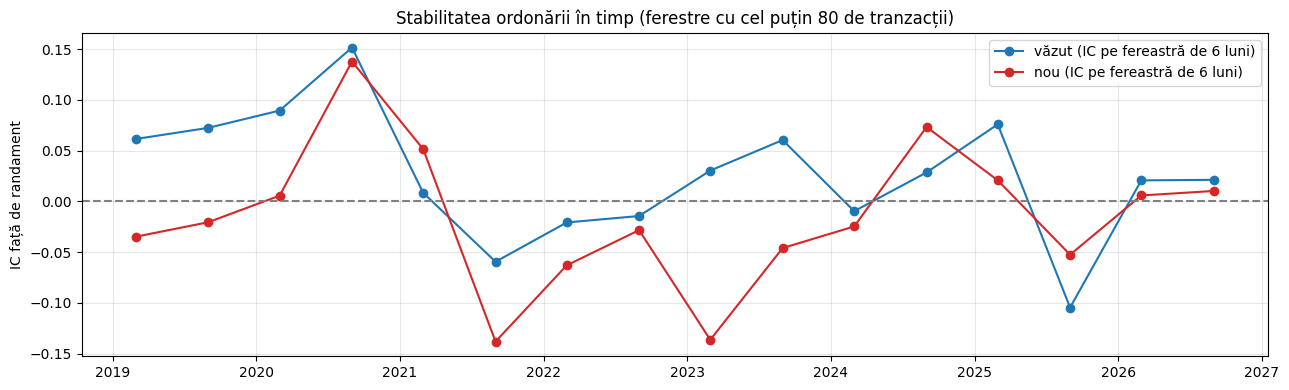

In [7]:
fig, ax = plt.subplots(figsize=(13, 4))
for grup, color in [("văzut", "tab:blue"), ("nou", "tab:red")]:
    pts = []
    for w, g in pred.loc[pred["grup"].eq(grup)].groupby("window"):
        pts.append((w, ic(g)[0] if len(g) > 80 else np.nan))
    x, y_ = zip(*pts)
    ax.plot(x, y_, marker="o", color=color, label=f"{grup} (IC pe fereastră de 6 luni)")
ax.axhline(0, color="gray", linestyle="--")
ax.set_ylabel("IC față de randament")
ax.set_title("Stabilitatea ordonării în timp (ferestre cu cel puțin 80 de tranzacții)")
ax.legend()
ax.grid(alpha=0.3)
fig.tight_layout()
plt.show()

### Randamentul pe cvintile ale probabilității

Împărțim tranzacțiile din fiecare strategie și fereastră în 5 grupe după rangul lui `p` (Q1 = cele mai slabe, Q5 = cele mai bune)
și arătăm randamentul mediu și rata de câștig. `Q5 − Q1` are interval de încredere din bootstrap lunar.

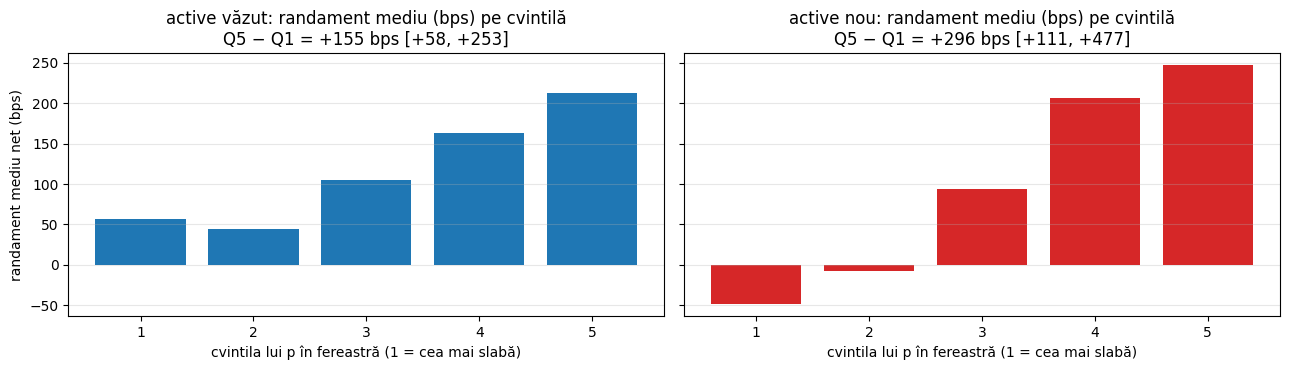

active văzut  perioada A    : Q5 − Q1 =   +431 bps [+182, +699]; win rate Q1 0.278 → Q5 0.478
active văzut  perioada B    : Q5 − Q1 =    +61 bps [-27, +149]; win rate Q1 0.340 → Q5 0.390
active văzut  perioada toate: Q5 − Q1 =   +155 bps [+58, +253]; win rate Q1 0.325 → Q5 0.413
active nou    perioada A    : Q5 − Q1 =   +725 bps [+305, +1204]; win rate Q1 0.266 → Q5 0.397


active nou    perioada B    : Q5 − Q1 =   +143 bps [-24, +310]; win rate Q1 0.325 → Q5 0.367
active nou    perioada toate: Q5 − Q1 =   +296 bps [+111, +477]; win rate Q1 0.309 → Q5 0.374


n    win      bps
      q                      
văzut 1  2241  0.325   56.679
      2  2271  0.336   44.657
      3  2277  0.358  104.415
      4  2271  0.391  163.503
      5  2313  0.413  212.009
nou   1  1985  0.309  -48.815
      2  2020  0.319   -7.083
      3  2018  0.334   93.447
      4  2020  0.361  206.812
      5  2059  0.374  247.163

In [8]:
def quintiles(df, seed=0):
    d = df.reset_index(drop=True)
    d["q"] = np.minimum((d.groupby(["strategy", "window"])["p"].rank(pct=True, method="first") * 5).astype(int), 4) + 1
    mb = d["decision_time"].dt.strftime("%Y-%m")
    mi = pd.factorize(mb)[0]
    nm = mi.max() + 1
    rng = np.random.default_rng(seed)
    idx = rng.integers(0, nm, size=(N_BOOT, nm))
    s = np.zeros((5, nm)); c = np.zeros((5, nm))
    for q in range(1, 6):
        m = d["q"].to_numpy() == q
        s[q - 1] = np.bincount(mi[m], weights=d["trade_return"].to_numpy()[m], minlength=nm)
        c[q - 1] = np.bincount(mi[m], minlength=nm)
    diff = (s[4][idx].sum(1) / c[4][idx].sum(1) - s[0][idx].sum(1) / c[0][idx].sum(1)) * 1e4
    base = (s[4].sum() / c[4].sum() - s[0].sum() / c[0].sum()) * 1e4
    g = d.groupby("q").agg(n=("y", "size"), win=("y", "mean"), bps=("trade_return", lambda r: 1e4 * r.mean()))
    return g, (base, *np.quantile(diff, [0.025, 0.975]))


fig, axes = plt.subplots(1, 2, figsize=(13, 3.8), sharey=True)
for ax, grup in zip(axes, ["văzut", "nou"]):
    g, d = quintiles(pred.loc[pred["grup"].eq(grup)])
    ax.bar(g.index, g["bps"], color="tab:blue" if grup == "văzut" else "tab:red")
    ax.set_title(f"active {grup}: randament mediu (bps) pe cvintilă\nQ5 − Q1 = {d[0]:+.0f} bps [{d[1]:+.0f}, {d[2]:+.0f}]")
    ax.set_xlabel("cvintila lui p în fereastră (1 = cea mai slabă)")
    ax.grid(alpha=0.3, axis="y")
axes[0].set_ylabel("randament mediu net (bps)")
fig.tight_layout()
plt.show()
for grup in ["văzut", "nou"]:
    for per in ["A", "B", "toate"]:
        sub = pred.loc[pred["grup"].eq(grup)] if per == "toate" else pred.loc[pred["grup"].eq(grup) & pred["perioadă"].eq(per)]
        g, d = quintiles(sub)
        print(f"active {grup:6s} perioada {per:5s}: Q5 − Q1 = {d[0]:+6.0f} bps [{d[1]:+.0f}, {d[2]:+.0f}];"
              f" win rate Q1 {g.loc[1, 'win']:.3f} → Q5 {g.loc[5, 'win']:.3f}")
pd.concat({grup: quintiles(pred.loc[pred["grup"].eq(grup)])[0] for grup in ["văzut", "nou"]}).round(3)

## 2. Valoarea economică a sizing-ului

Pentru fiecare grup de active și perioadă: Sharpe-ul fiecărei reguli (aceeași expunere medie), `Δ vs U` cu interval de
încredere, și p-ul testului de permutare pentru regulile informative (`O`, `R`, `P`). Sub fiecare tabel: `R − O` (modelul
față de prior-ul pe activ) și `R×D1 − D1` (cât adaugă modelul peste dimensionarea invers-vol).

### Active noi (dovada curată pentru transfer)

In [9]:
show_econ(pred.loc[pred["grup"].eq("nou")], "ACTIVE NOI, toată perioada")
for per in ["A", "B", "C"]:
    sub = pred.loc[pred["grup"].eq("nou") & pred["perioadă"].eq(per)]
    if len(sub) > 200:
        show_econ(sub, f"ACTIVE NOI, perioada {per}")

ACTIVE NOI, toată perioada: n=10102


,Sharpe,Δ vs U,IC jos,IC sus,p permutare
variantă,,,,,
U,0.825,0.000,0.000,0.000,NaN
D1,0.986,0.162,-0.000,0.362,NaN
O,0.843,0.018,-0.039,0.082,0.241
R,0.941,0.116,0.037,0.229,0.000
P,0.896,0.071,0.015,0.156,0.001
R×D1,1.082,0.258,0.098,0.488,NaN


   comparații pereche (ΔSharpe [IC 95 %]): R − O = +0.099 [-0.003, +0.225]; R×D1 − D1 = +0.096 [+0.024, +0.187]


ACTIVE NOI, perioada A: n=2642


,Sharpe,Δ vs U,IC jos,IC sus,p permutare
variantă,,,,,
U,1.196,0.000,0.000,0.000,NaN
D1,1.328,0.132,-0.155,0.438,NaN
O,1.160,-0.036,-0.177,0.069,0.723
R,1.295,0.099,-0.042,0.362,0.023
P,1.271,0.076,-0.049,0.285,0.024
R×D1,1.509,0.313,0.014,0.700,NaN


   comparații pereche (ΔSharpe [IC 95 %]): R − O = +0.135 [-0.030, +0.484]; R×D1 − D1 = +0.181 [+0.032, +0.387]


ACTIVE NOI, perioada B: n=7168


,Sharpe,Δ vs U,IC jos,IC sus,p permutare
variantă,,,,,
U,0.597,0.000,0.000,0.000,NaN
D1,0.896,0.300,0.120,0.532,NaN
O,0.645,0.049,-0.028,0.135,0.098
R,0.703,0.106,0.011,0.216,0.004
P,0.652,0.055,-0.001,0.121,0.019
R×D1,0.954,0.358,0.144,0.631,NaN


   comparații pereche (ΔSharpe [IC 95 %]): R − O = +0.057 [-0.062, +0.196]; R×D1 − D1 = +0.058 [-0.026, +0.157]
ACTIVE NOI, perioada C: n=292


,Sharpe,Δ vs U,IC jos,IC sus,p permutare
variantă,,,,,
U,0.129,0.000,NaN,NaN,NaN
D1,0.869,0.740,NaN,NaN,NaN
O,0.332,0.203,NaN,NaN,0.176
R,0.467,0.338,NaN,NaN,0.070
P,0.246,0.117,NaN,NaN,0.127
R×D1,1.171,1.042,NaN,NaN,NaN


   comparații pereche (ΔSharpe [IC 95 %]): R − O = +0.135 [+nan, +nan]; R×D1 − D1 = +0.302 [+nan, +nan]


### Verdictul ipotezelor înghețate (active noi, toată perioada)

Calculat automat din specificație: H1 IC(p, randament) cu interval deasupra lui 0; H2 `R` bate `U` cu p de permutare < 0.05;
H3 `R − O` cu interval deasupra lui 0; H4 `R×D1 − D1` cu interval deasupra lui 0.

In [10]:
nou_all = pred.loc[pred["grup"].eq("nou")]
c1 = ic(nou_all)
tab_n, pairs_n = econ(nou_all)
verdict = pd.DataFrame([
    {"ipoteză": "H1  IC(p, randament) > 0", "valoare": fmt(c1), "confirmată": c1[1] > 0},
    {"ipoteză": "H2  R bate U (permutare)", "valoare": f"Δ Sharpe {tab_n.loc['R', 'Δ vs U']:+.3f} [{tab_n.loc['R', 'IC jos']:+.3f}, {tab_n.loc['R', 'IC sus']:+.3f}], p = {tab_n.loc['R', 'p permutare']:.3f}",
     "confirmată": tab_n.loc["R", "p permutare"] < 0.05},
    {"ipoteză": "H3  R − O > 0 (față de prior pe activ)", "valoare": f"{pairs_n['R − O'][0]:+.3f} [{pairs_n['R − O'][1]:+.3f}, {pairs_n['R − O'][2]:+.3f}]",
     "confirmată": pairs_n["R − O"][1] > 0},
    {"ipoteză": "H4  R×D1 − D1 > 0 (peste invers-vol)", "valoare": f"{pairs_n['R×D1 − D1'][0]:+.3f} [{pairs_n['R×D1 − D1'][1]:+.3f}, {pairs_n['R×D1 − D1'][2]:+.3f}]",
     "confirmată": pairs_n["R×D1 − D1"][1] > 0},
]).set_index("ipoteză")
verdict

,valoare,confirmată
ipoteză,,
"H1 IC(p, randament) > 0","-0.013 [-0.043, +0.017]",False
H2 R bate U (permutare),"Δ Sharpe +0.116 [+0.037, +0.229], p = 0.000",True
H3 R − O > 0 (față de prior pe activ),"+0.099 [-0.003, +0.225]",False
H4 R×D1 − D1 > 0 (peste invers-vol),"+0.096 [+0.024, +0.187]",True


### Active vechi („văzute”, doar pentru comparație)

In [11]:
show_econ(pred.loc[pred["grup"].eq("văzut")], "ACTIVE VECHI, toată perioada")
for per in ["A", "B", "C"]:
    sub = pred.loc[pred["grup"].eq("văzut") & pred["perioadă"].eq(per)]
    if len(sub) > 200:
        show_econ(sub, f"ACTIVE VECHI, perioada {per}")

ACTIVE VECHI, toată perioada: n=11373


,Sharpe,Δ vs U,IC jos,IC sus,p permutare
variantă,,,,,
U,1.140,0.000,0.000,0.000,NaN
D1,1.366,0.226,0.080,0.389,NaN
O,1.156,0.016,-0.047,0.073,0.240
R,1.217,0.077,-0.000,0.169,0.003
P,1.186,0.046,-0.015,0.115,0.022
R×D1,1.395,0.255,0.097,0.453,NaN


   comparații pereche (ΔSharpe [IC 95 %]): R − O = +0.061 [-0.026, +0.171]; R×D1 − D1 = +0.029 [-0.039, +0.113]


ACTIVE VECHI, perioada A: n=3128


,Sharpe,Δ vs U,IC jos,IC sus,p permutare
variantă,,,,,
U,1.663,0.000,0.000,0.000,NaN
D1,2.050,0.387,0.087,0.697,NaN
O,1.621,-0.042,-0.213,0.044,0.746
R,1.789,0.126,-0.005,0.295,0.007
P,1.728,0.065,-0.089,0.196,0.073
R×D1,2.168,0.505,0.185,0.826,NaN


   comparații pereche (ΔSharpe [IC 95 %]): R − O = +0.168 [+0.005, +0.466]; R×D1 − D1 = +0.118 [+0.010, +0.221]


ACTIVE VECHI, perioada B: n=7926


,Sharpe,Δ vs U,IC jos,IC sus,p permutare
variantă,,,,,
U,0.803,0.000,0.000,0.000,NaN
D1,1.110,0.307,0.119,0.560,NaN
O,0.870,0.066,-0.022,0.170,0.038
R,0.853,0.050,-0.067,0.178,0.093
P,0.840,0.037,-0.047,0.132,0.108
R×D1,1.109,0.305,0.092,0.588,NaN


   comparații pereche (ΔSharpe [IC 95 %]): R − O = -0.017 [-0.146, +0.101]; R×D1 − D1 = -0.002 [-0.087, +0.092]
ACTIVE VECHI, perioada C: n=319


,Sharpe,Δ vs U,IC jos,IC sus,p permutare
variantă,,,,,
U,0.376,0.000,NaN,NaN,NaN
D1,0.278,-0.099,NaN,NaN,NaN
O,0.382,0.006,NaN,NaN,0.481
R,0.394,0.018,NaN,NaN,0.463
P,0.415,0.038,NaN,NaN,0.323
R×D1,0.291,-0.085,NaN,NaN,NaN


   comparații pereche (ΔSharpe [IC 95 %]): R − O = +0.012 [+nan, +nan]; R×D1 − D1 = +0.014 [+nan, +nan]


### Pe strategii (active noi)

Care strategii contribuie la IC și la câștigul de sizing.

In [12]:
rows = []
for s in SS:
    g = pred.loc[pred["grup"].eq("nou") & pred["strategy"].eq(s)]
    tab, pairs = econ(g)
    rows.append({"strategie": s, "n": len(g), "IC randament": fmt(ic(g)), "IC etichetă": fmt(ic(g, target="y")),
                 "Δ log loss": g["dll"].mean(), "Sharpe U": tab.loc["U", "Sharpe"], "Δ Sharpe R": tab.loc["R", "Δ vs U"],
                 "IC R": f"[{tab.loc['R', 'IC jos']:+.2f}, {tab.loc['R', 'IC sus']:+.2f}]", "p permutare R": tab.loc["R", "p permutare"],
                 "R − O": f"{pairs['R − O'][0]:+.2f}"})
pd.DataFrame(rows).set_index("strategie").round(3)

,n,IC randament,IC etichetă,Δ log loss,Sharpe U,Δ Sharpe R,IC R,p permutare R,R − O
strategie,,,,,,,,,
RSI,4286,"-0.112 [-0.153, -0.072]","+0.005 [-0.036, +0.050]",0.005,-0.171,0.051,"[-0.14, +0.22]",0.254,-0.01
DONCHIAN,1549,"+0.088 [+0.025, +0.148]","+0.089 [+0.034, +0.142]",-0.008,0.928,0.102,"[-0.01, +0.23]",0.007,+0.17
TIS,1329,"+0.028 [-0.046, +0.110]","+0.170 [+0.091, +0.250]",-0.013,0.917,0.025,"[-0.03, +0.11]",0.176,+0.04
SUPERTREND,2938,"+0.060 [-0.005, +0.123]","+0.050 [-0.013, +0.114]",0.004,0.557,0.194,"[+0.02, +0.38]",0.000,+0.15


# Partea II — explorare (nu e înghețată)

Descriere, nu test. Rulat pe toate datele (active vechi și noi). Întrebări: (a) ce contribuie la ordonare, (b) ce clasă de
model extrage cel mai mult, (c) **prezice log loss-ul câștigul economic?**

Pentru fiecare combinație set de features × model: `Δ log loss` față de prior, IC față de randament, `Δ Sharpe` al regulii pe
rang față de sizing uniform (toate tranzacțiile, active vechi și noi).

In [13]:
SETS = {"doar strategie": lambda s: LIB[s], "+ FT": lambda s: LIB[s] + FT, "+ FV": lambda s: LIB[s] + FV,
        "+ FT + FV (M1)": lambda s: LIB[s] + FT + FV, "+ FT + FV + flux": lambda s: LIB[s] + FT + FV + FF,
        "doar volatilitate 30z": lambda s: ["v_rvol_30d"]}
MODELS = {"LR C=0.003": lambda: lr_model(0.003), "LR C=0.01": lambda: lr_model(0.01), "LR C=0.1": lambda: lr_model(0.1),
          "LR C=1": lambda: lr_model(1.0), "HGB adâncime 2": hgb_model}
rows = []
for sname, ff in SETS.items():
    for mname, make in MODELS.items():
        pr = walk_forward(ff, make)
        pr["dll"] = ll(pr["p"].to_numpy(), pr["y"].to_numpy()) - ll(pr["prior"].to_numpy(), pr["y"].to_numpy())
        pr = pr.reset_index(drop=True)
        mi = month_blocks(pr)
        nm = mi.max() + 1
        r = pr["trade_return"].to_numpy() * NOTIONAL
        Wr = rank_w(pr, "p"); Wr = Wr / Wr.mean()
        dsh = sharpe(np.bincount(mi, weights=Wr * r, minlength=nm)) - sharpe(np.bincount(mi, weights=r, minlength=nm))
        c = ic(pr)
        rows.append({"features": sname, "model": mname, "Δ log loss": pr["dll"].mean(), "IC randament": c[0],
                     "IC jos": c[1], "IC sus": c[2], "Δ Sharpe (rang)": dsh})
ablation = pd.DataFrame(rows)
ablation.pivot(index="features", columns="model", values="IC randament").round(3)

model,HGB adâncime 2,LR C=0.003,LR C=0.01,LR C=0.1,LR C=1
features,,,,,
+ FT,-0.001,-0.021,-0.012,-0.004,-0.003
+ FT + FV (M1),0.014,0.001,0.012,0.021,0.022
+ FT + FV + flux,0.012,-0.000,0.011,0.020,0.021
+ FV,0.004,-0.002,0.007,0.011,0.012
doar strategie,-0.023,-0.027,-0.024,-0.022,-0.022
doar volatilitate 30z,0.037,0.096,0.096,0.096,0.096


In [14]:
display(ablation.pivot(index="features", columns="model", values="Δ log loss").round(4))
display(ablation.pivot(index="features", columns="model", values="Δ Sharpe (rang)").round(3))
print("Spearman între Δ log loss și Δ Sharpe (rang), pe cele", len(ablation), "combinații:",
      round(spearmanr(ablation["Δ log loss"], ablation["Δ Sharpe (rang)"]).statistic, 2))
print("Spearman între IC și Δ Sharpe (rang):", round(spearmanr(ablation["IC randament"], ablation["Δ Sharpe (rang)"]).statistic, 2))
print("Spearman între Δ log loss și IC:", round(spearmanr(ablation["Δ log loss"], ablation["IC randament"]).statistic, 2))

model,HGB adâncime 2,LR C=0.003,LR C=0.01,LR C=0.1,LR C=1
features,,,,,
+ FT,0.0048,-0.0014,-0.0008,0.0028,0.0056
+ FT + FV (M1),0.0048,-0.0013,0.0001,0.0055,0.0091
+ FT + FV + flux,0.0046,-0.0011,0.0006,0.0068,0.0114
+ FV,0.0061,0.0000,0.0011,0.0047,0.0068
doar strategie,0.0038,0.0000,0.0004,0.0021,0.0030
doar volatilitate 30z,0.0034,-0.0003,-0.0003,0.0001,0.0004


model,HGB adâncime 2,LR C=0.003,LR C=0.01,LR C=0.1,LR C=1
features,,,,,
+ FT,0.105,0.093,0.110,0.116,0.116
+ FT + FV (M1),0.110,0.083,0.103,0.111,0.110
+ FT + FV + flux,0.103,0.085,0.105,0.114,0.112
+ FV,0.050,0.005,0.029,0.047,0.048
doar strategie,0.020,0.004,0.018,0.028,0.030
doar volatilitate 30z,0.023,0.162,0.162,0.162,0.162


Spearman între Δ log loss și Δ Sharpe (rang), pe cele 30 combinații: 0.11
Spearman între IC și Δ Sharpe (rang): 0.64
Spearman între Δ log loss și IC: 0.21


## Este doar volatilitate? (explorare post-hoc, active noi)

Ablația de mai sus arată că un model cu **o singură** variabilă (volatilitatea pe 30 de zile) are cel mai bun IC și cel mai
bun `Δ Sharpe`, deși log loss-ul lui e foarte rău (nivelul absolut al volatilității nu e comparabil între active: monedele noi
sunt mai volatile, deci probabilitățile ies extreme). Întrebare: câștigul lui M1 este volatilitate deghizată?
Comparăm pe activele noi sizing-ul pe rang cu M1, cu modelul care folosește doar volatilitatea și cu modelul fără nicio
variabilă de volatilitate (strategie + trend FT). `R(x)` = regula pe rang aplicată probabilității modelului x.

In [15]:
pr_vol = walk_forward(lambda s: ["v_rvol_30d"], lambda: lr_model(0.01))
pr_ft = walk_forward(lambda s: LIB[s] + FT, lambda: lr_model(0.01))
pr_lib = walk_forward(lambda s: LIB[s], lambda: lr_model(0.01))


def aligned(pr, base):
    w = pd.Series(rank_w(pr, "p"), index=pd.MultiIndex.from_frame(pr[["row", "window"]]))
    return w.reindex(pd.MultiIndex.from_frame(base[["row", "window"]])).to_numpy()


def paired_compare(base, extra, pairs, seed=0):
    base = base.reset_index(drop=True)
    W = {"U": np.ones(len(base)), "D1": base["inv"].to_numpy(), **{k: aligned(v, base) for k, v in extra.items()}}
    W["R(M1)"] = rank_w(base, "p")
    for k in list(extra) + ["M1"]:
        key = "R(M1)" if k == "M1" else k
        W[key + "×D1"] = W[key] * W["D1"]
    W = {k: v / np.nanmean(v) for k, v in W.items()}
    mi = month_blocks(base)
    nm = mi.max() + 1
    r = base["trade_return"].to_numpy() * NOTIONAL
    M = {k: np.bincount(mi, weights=np.nan_to_num(w, nan=1.0) * r, minlength=nm) for k, w in W.items()}
    idx = np.random.default_rng(seed).integers(0, nm, size=(N_BOOT, nm))
    B = {k: sharpe(m[idx]) for k, m in M.items()}
    rows = [{"variantă": k, "Sharpe": sharpe(M[k]), "Δ vs U": sharpe(M[k]) - sharpe(M["U"])} for k in M]
    out = pd.DataFrame(rows).set_index("variantă")
    cmp = pd.DataFrame([{"comparație": f"{a} − {b}", "Δ Sharpe": sharpe(M[a]) - sharpe(M[b]),
                         "IC jos": np.quantile(B[a] - B[b], 0.025), "IC sus": np.quantile(B[a] - B[b], 0.975)}
                        for a, b in pairs]).set_index("comparație")
    return out, cmp


EXTRA = {"R(vol)": pr_vol, "R(FT)": pr_ft, "R(lib)": pr_lib}
PAIRS = [("R(M1)", "R(vol)"), ("R(FT)", "R(vol)"), ("R(lib)", "U"), ("R(FT)", "U"), ("R(vol)", "U"),
         ("R(M1)×D1", "D1"), ("R(FT)×D1", "D1"), ("R(vol)×D1", "D1"), ("R(M1)×D1", "R(vol)×D1")]
nou_df = pred.loc[pred["grup"].eq("nou")]
for label, sub in [("toată perioada", nou_df), ("perioada A", nou_df.loc[nou_df["perioadă"].eq("A")]),
                   ("perioada B", nou_df.loc[nou_df["perioadă"].eq("B")])]:
    t, c = paired_compare(sub, EXTRA, PAIRS)
    print(f"ACTIVE NOI, {label}, n = {len(sub)}")
    display(t.round(3).T)
    display(c.round(3))

ACTIVE NOI, toată perioada, n = 10102


variantă,U,D1,R(vol),R(FT),R(lib),R(M1),R(vol)×D1,R(FT)×D1,R(lib)×D1,R(M1)×D1
Sharpe,0.825,0.986,0.990,0.946,0.864,0.941,1.120,1.089,0.998,1.082
Δ vs U,0.000,0.162,0.165,0.122,0.040,0.116,0.296,0.265,0.173,0.258


,Δ Sharpe,IC jos,IC sus
comparație,,,
R(M1) − R(vol),-0.049,-0.130,0.031
R(FT) − R(vol),-0.044,-0.127,0.041
R(lib) − U,0.040,-0.049,0.146
R(FT) − U,0.122,0.045,0.231
R(vol) − U,0.165,0.078,0.285
R(M1)×D1 − D1,0.096,0.024,0.187
R(FT)×D1 − D1,0.103,0.033,0.191
R(vol)×D1 − D1,0.134,0.057,0.236
R(M1)×D1 − R(vol)×D1,-0.038,-0.122,0.044


ACTIVE NOI, perioada A, n = 2642


variantă,U,D1,R(vol),R(FT),R(lib),R(M1),R(vol)×D1,R(FT)×D1,R(lib)×D1,R(M1)×D1
Sharpe,1.196,1.328,1.212,1.293,1.296,1.295,1.400,1.501,1.445,1.509
Δ vs U,0.000,0.132,0.017,0.098,0.100,0.099,0.205,0.305,0.250,0.313


,Δ Sharpe,IC jos,IC sus
comparație,,,
R(M1) − R(vol),0.083,-0.024,0.240
R(FT) − R(vol),0.081,-0.031,0.234
R(lib) − U,0.100,-0.074,0.333
R(FT) − U,0.098,-0.040,0.352
R(vol) − U,0.017,-0.077,0.167
R(M1)×D1 − D1,0.181,0.032,0.387
R(FT)×D1 − D1,0.173,0.022,0.374
R(vol)×D1 − D1,0.072,-0.020,0.191
R(M1)×D1 − R(vol)×D1,0.108,-0.018,0.262


ACTIVE NOI, perioada B, n = 7168


variantă,U,D1,R(vol),R(FT),R(lib),R(M1),R(vol)×D1,R(FT)×D1,R(lib)×D1,R(M1)×D1
Sharpe,0.597,0.896,0.831,0.712,0.595,0.703,1.059,0.966,0.872,0.954
Δ vs U,0.000,0.300,0.234,0.115,-0.002,0.106,0.462,0.369,0.275,0.358


,Δ Sharpe,IC jos,IC sus
comparație,,,
R(M1) − R(vol),-0.128,-0.243,-0.020
R(FT) − R(vol),-0.119,-0.245,0.001
R(lib) − U,-0.002,-0.110,0.112
R(FT) − U,0.115,0.022,0.228
R(vol) − U,0.234,0.116,0.378
R(M1)×D1 − D1,0.058,-0.026,0.157
R(FT)×D1 − D1,0.069,-0.013,0.167
R(vol)×D1 − D1,0.163,0.065,0.279
R(M1)×D1 − R(vol)×D1,-0.105,-0.212,-0.007


## Robustețe (pe activele noi, după îngheț)

IC pe ani calendaristici și efectul eliminării tranzacțiilor extreme din Sharpe (IC pe ranguri este robust prin construcție).

In [16]:
nou = pred.loc[pred["grup"].eq("nou")].reset_index(drop=True)
rows = []
for yv, g in nou.groupby(nou["decision_time"].dt.year):
    if len(g) > 150:
        rows.append({"an": yv, "n": len(g), "IC randament": fmt(ic(g)), "Δ log loss": g["dll"].mean()})
display(pd.DataFrame(rows).set_index("an"))
q1, q99 = nou["trade_return"].quantile([0.01, 0.99])
trimmed = nou.loc[(nou["trade_return"] > q1) & (nou["trade_return"] < q99)]
tab, pairs = econ(trimmed)
print("fără 1 % din cozi (active noi): n =", len(trimmed))
display(tab.round(3))

,n,IC randament,Δ log loss
an,,,
2019,349,"-0.072 [-0.157, +0.012]",0.004178
2020,1184,"+0.042 [-0.038, +0.120]",-0.003766
2021,1683,"+0.013 [-0.068, +0.086]",0.002330
2022,1174,"-0.089 [-0.162, -0.026]",0.005231
2023,1673,"-0.077 [-0.122, -0.042]",0.006751
2024,1562,"-0.011 [-0.083, +0.068]",-0.002958
2025,1308,"+0.002 [-0.070, +0.082]",-0.003445
2026,1169,"-0.008 [-0.062, +0.052]",-0.002662


fără 1 % din cozi (active noi): n = 9898


,Sharpe,Δ vs U,IC jos,IC sus,p permutare
variantă,,,,,
U,0.435,0.000,0.000,0.000,NaN
D1,0.671,0.235,0.045,0.451,NaN
O,0.455,0.020,-0.051,0.094,0.279
R,0.541,0.106,0.014,0.212,0.000
P,0.495,0.060,-0.003,0.134,0.014
R×D1,0.726,0.290,0.075,0.549,NaN


## Concluzii

Cifrele vin din output-urile de deasupra. Rularea este deterministă (seed-uri fixe, date în cache cu `DATA_END` fix).

**1. Verdictul ipotezelor înghețate, pe activele noi (singura dovadă curată).**

| Ipoteză | Rezultat | Confirmată |
|---|---|---|
| H1: IC(p, randament) > 0 | −0.013 [−0.043, +0.017] | nu |
| H2: sizing pe rang (`R`) bate sizing uniform | Δ Sharpe +0.116 [+0.037, +0.229], permutare p < 0.001 | **da** |
| H3: `R` bate prior-ul pe activ (`O`) | +0.099 [−0.003, +0.225] | nu (la limită) |
| H4: `R×D1` bate dimensionarea invers-vol `D1` | +0.096 [+0.024, +0.187] | **da** |

Așteptările pre-înregistrate erau: H1 ≈ +0.05 (greșit, nu s-a confirmat), H2 +0.05…+0.13 (corect), H3 și H4 cu interval care
include 0 (H3 corect, H4 greșit: a ieșit pozitiv).

**2. Transferul între active există, dar e modest și neuniform în timp.**
* Un model antrenat doar pe cele 20 de active vechi ordonează tranzacțiile pe activele noi: rata de câștig crește de la 0.309 în
  prima cvintilă la 0.374 în ultima, iar IC față de etichetă este +0.054 [+0.024, +0.083]. Diferența de randament Q5 − Q1 este
  +296 bps [+111, +477].
* **Pe perioade:** în A (2019–2021) efectul e mare (Q5 − Q1 = +725 bps [+305, +1204], rata de câștig 0.266 → 0.397, Δ log
  loss −0.0027). În B (2021-09 → 2026-08) e mult mai slab (+143 bps [−24, +310], IC pe etichetă +0.033 [−0.002, +0.068], Δ log
  loss +0.0020). Perioada C (292 tranzacții) nu poate decide.
* Pe activele vechi imaginea e similară (Q5 − Q1 +155 bps [+58, +253]; în A +431, în B +61 cu interval care include 0).

**3. De ce H1 nu se confirmă, deși ordonarea după etichetă e reală.** `p` este o probabilitate de *câștig*, iar rangul
randamentului depinde și de mărimea pierderilor. Pe activele noi, la RSI IC-ul față de randament este chiar negativ
(−0.112 [−0.153, −0.072]) cu IC pe etichetă ≈ 0 (+0.005), iar IC pe ani este negativ în 2022 (−0.089) și 2023 (−0.077).
La Donchian IC față de randament e +0.088 [+0.025, +0.148], la SuperTrend +0.060, la TIS +0.028 (IC pe etichetă +0.170
[+0.091, +0.250]). Prin urmare, semnul ordonării după randament depinde de strategie și de perioadă, iar ordonarea după etichetă e mai stabilă.

**4. Valoarea economică: sizing-ul cu modelul bate sizing-ul uniform și sizing-ul cu prior-ul, dar nu și o regulă simplă.**
* **Prior-ul pe activ nu valorează nimic ca sizing:** `O` +0.018 [−0.039, +0.082] (permutare p = 0.24).
* **`R` bate uniformul** pe activele noi în ambele perioade (A +0.099, permutare p = 0.023; B +0.106 [+0.011, +0.216],
  p = 0.004), robust la eliminarea a 1 % din tranzacțiile extreme (+0.106 [+0.014, +0.212]). Cel mai mult contribuie
  SuperTrend (+0.194 [+0.02, +0.38], p < 0.001) și Donchian (+0.102, p = 0.007).
* **Peste dimensionarea invers-vol (`D1`)** modelul adaugă +0.096 [+0.024, +0.187] pe activele noi, dar aproape tot în A
  (+0.181 [+0.032, +0.387]); în B +0.058 [−0.026, +0.157]. Pe activele vechi: A +0.118 [+0.010, +0.221], B −0.002.
* `D1` singur: +0.162 [0.000, +0.362] pe activele noi (A +0.132, B +0.300 [+0.120, +0.532]); pe cele vechi A +0.387, B +0.307.

**5. Explorare post-hoc: majoritatea valorii este volatilitate.** Un model cu o singură variabilă (volatilitatea pe 30 de
zile) are sizing pe rang cu Δ Sharpe +0.165 [+0.078, +0.285] pe activele noi, față de +0.116 la M1.
* M1 − vol = −0.049 [−0.130, +0.031]; în B −0.128 [−0.243, −0.020]; în A +0.083 [−0.024, +0.240].
* Peste dimensionarea invers-vol, volatilitatea adaugă +0.134 [+0.057, +0.236], M1 +0.096; `R(M1)×D1 − R(vol)×D1` = −0.038
  [−0.122, +0.044] (în B −0.105 [−0.212, −0.007]).
* **Trendul contează în alt regim:** modelul fără nicio variabilă de volatilitate (strategie + FT) are +0.122 [+0.045, +0.231];
  în A el face +0.098 față de +0.017 pentru volatilitate, în B +0.115 față de +0.234. Volatilitatea domină în B, trendul în A,
  iar M1 le amestecă și iese între ele.
* Modelul cu o singură variabilă are un log loss foarte prost (+0.096): nivelul absolut al volatilității nu e comparabil între
  active, deci probabilitățile ies extreme. Cu toate astea are cel mai bun `Δ Sharpe` din tot grid-ul.

**6. Log loss-ul nu prezice valoarea economică.** Pe cele 30 de combinații (6 seturi de features × 5 modele), Spearman între
Δ log loss și Δ Sharpe (rang) este +0.11, adică practic nul și de semn contrar celui așteptat. Între IC față de randament și
Δ Sharpe este +0.64. Modelele alese după log loss ar fi alese greșit pentru sizing. Aceasta confirmă obiecția că verdictul
din `solid/cross_asset_transfer_meta_labeling.ipynb`, bazat pe log loss și AUC, nu măsura ce contează economic.

**Răspunsul la întrebare.**
* *Meta-labeling-ul (probabilitate de câștig) față de prior ca **probabilitate**:* nu aduce un avantaj consistent (Δ log loss
  +0.0006 pe active noi; negativ doar în A).
* *Ca **sizing**:* da, un sizing pe rang bate sizing-ul uniform și sizing-ul cu prior-ul pe activele noi, pe date nevăzute de nicio
  analiză anterioară. Valoarea este însă aproape tot informație de **volatilitate** (și, în alt regim, de **trend**), nu un
  semnal specific unui meta-model, iar o regulă cu o singură variabilă face la fel de bine sau mai bine.
* *Practic:* dimensionarea invers-vol rămâne cea mai solidă îmbunătățire. Un model care combină volatilitate și trend nu a
  arătat un avantaj clar peste ea.

**Limite.**
* Activele noi sunt independente de cele vechi doar în secțiune transversală: trăiesc în aceleași perioade și au aceeași
  componentă de piață, deci cele două seturi de rezultate nu sunt două experimente independente în timp.
* Cele 40 de active există și azi; active dispărute lipsesc (efect de supraviețuire).
* Perioada C are ~3 luni și nu poate decide. Notebook-ul se poate rula din nou cu un `DATA_END` mai târziu (specificația rămâne
  aceeași) pentru ca C să devină informativă; abia după 6–12 luni.
* Din cele 4 ipoteze înghețate, H2 și H4 au p mici, dar nu am corectat pentru comparații multiple. Secțiunile „Este doar
  volatilitate?” și ablațiile sunt explorare post-hoc: descriu, nu testează.
* Sharpe-ul este calculat pe PnL lunar cu mărime per tranzacție, fără constrângeri de capital și cu costuri fixe de 5 bps.
* Modelul folosește doar features ale activului respectiv. Nu am testat features transversale sau de piață (care au dat
  ceasuri de regim în `meta_labeling_beating_the_prior.ipynb`).

**Ce merită făcut mai departe.**
* Rularea din nou pe date noi, cu specificația neschimbată.
* Un test înghețat, pe date noi, al unui sizing care combină explicit volatilitatea și trendul (de exemplu, două scoruri
  separate în loc de un singur model), deoarece cele două funcționează în regimuri diferite.
* Pentru predicția probabilității de câștig pe aceste strategii: nu merită alte seturi de features pe aceleași date.